In [2]:
!pip install -q ultralytics roboflow

In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("tran-ngoc-xuan-tin-k15-hcm-dpuid").project("vietnam-license-plate-h8t3n")
version = project.version(1)
dataset = version.download("yolov11")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Vietnam-license-plate-1 in yolov11:: 100%|██████████| 2022/2022 [00:00<00:00, 10814.91it/s]


In [4]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="vn_license_plate",
    patience=15,
    device=0
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Vietnam-license-plate-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, f

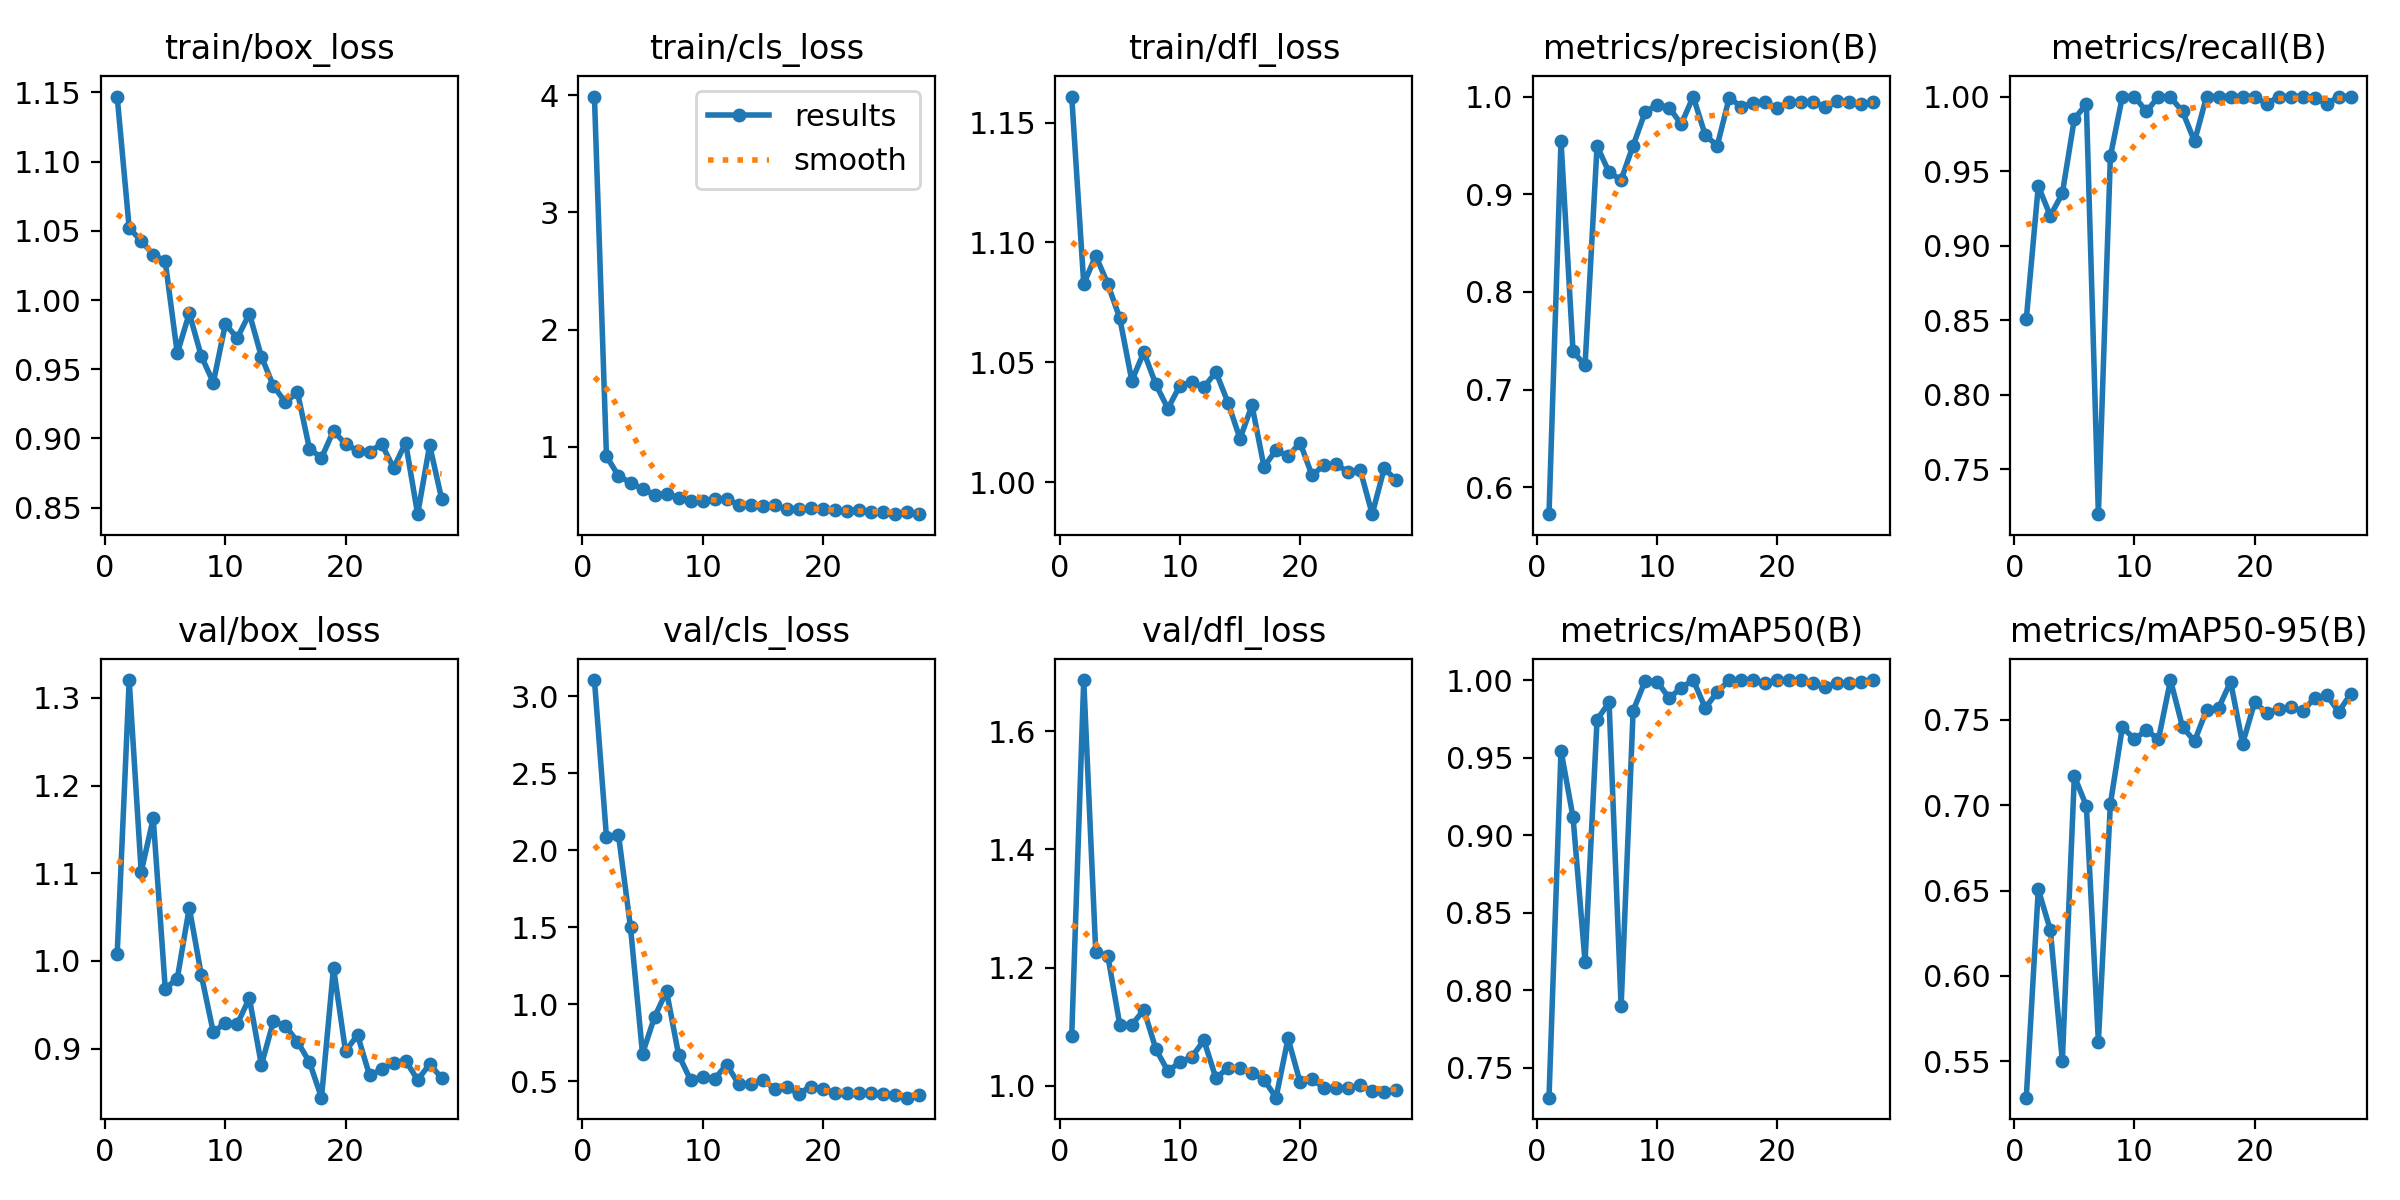

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'runs/detect/vn_license_plate/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requirements: Ultralytics requirement ['openvino>=2024.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 3 packages in 330ms
Prepared 2 packages in 719ms
Installed 2 packages in 16ms
 + openvino==2026.4.1
 + openvino-telemetry==2025.2.0

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


OpenVINO: starting export with openvino 2026.4.1-22982-e213a147257-releases/2026/4...


`torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
`torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.


OpenVINO: export success ✅ 3.7s, saved as 'runs/detect/vn_license_plate/weights/best_openvino_model/' (10.3 MB)

Export complete (4.0s)
Results saved to /content/runs/detect/vn_license_plate/weights/best_openvino_model
Predict:         yolo predict task=detect model=runs/detect/vn_license_plate/weights/best_openvino_model/ imgsz=640 
Validate:        yolo val task=detect model=runs/detect/vn_license_plate/weights/best_openvino_model/ imgsz=640 data=/content/Vietnam-license-plate-1/data.yaml 
Visualize:       https://netron.app
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'runs/detect/vn_license_plate/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Pytho

'runs/detect/vn_license_plate/weights/best.onnx'

In [5]:
from ultralytics import YOLO
from IPython.display import Image, display

# Hiển thị biểu đồ kết quả huấn luyện
display(Image(filename="runs/detect/vn_license_plate/results.png", width=800))

# Load model tốt nhất và export
best_model = YOLO("runs/detect/vn_license_plate/weights/best.pt")
best_model.export(format="openvino", imgsz=640)
best_model.export(format="onnx", imgsz=640)

In [6]:
!zip -r stage2_artifacts.zip \
    runs/detect/vn_license_plate/weights/best.pt \
    runs/detect/vn_license_plate/weights/best.onnx \
    runs/detect/vn_license_plate/weights/best_openvino_model \
    runs/detect/vn_license_plate/results.png

from google.colab import files
files.download("stage2_artifacts.zip")

  adding: runs/detect/vn_license_plate/weights/best.pt (deflated 10%)
  adding: runs/detect/vn_license_plate/weights/best.onnx (deflated 13%)
  adding: runs/detect/vn_license_plate/weights/best_openvino_model/ (stored 0%)
  adding: runs/detect/vn_license_plate/weights/best_openvino_model/best.bin (deflated 12%)
  adding: runs/detect/vn_license_plate/weights/best_openvino_model/best.xml (deflated 94%)
  adding: runs/detect/vn_license_plate/weights/best_openvino_model/metadata.yaml (deflated 37%)
  adding: runs/detect/vn_license_plate/results.png (deflated 8%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>